# Multilevel Monte Carlo in practice: a reservoir example

- Goal: how to use Multilevel Monte Carlo (MLMC) step by step (Giles 2015, [Multilevel Monte Carlo methods](https://doi.org/10.1017/S096249291500001X), Algorithm 1, p. 279).
- Simulator: a small toy, one run takes milliseconds. A real reservoir simulator takes minutes to hours per run, but **the steps are exactly the same**.

<img src="figures/sodir_waterflood_mobile_oil.png" alt="Water injection: water pushes oil from the injection well to the production well" style="width: 100%; max-width: 900px;">

*Water injection: water (blue) pushes oil (green) from the injection well to the production well. Some oil stays behind in the pores (immobile oil). Source: [Norwegian Offshore Directorate (Sodir)](https://www.sodir.no/48cd02/globalassets/1-sodir/fakta/produksjon/okt-utvinning/vanninjeksjon/mobile-oil.png).*

## 1. The problem

Oil is not in an underground lake: it sits in the tiny pores of rock 1–4 km down, like water in a sponge. To get it out, an injector well pumps water into the rock, and the water pushes the oil towards a producer well (figure above). From input to output:

$$
\underbrace{\theta}_{\text{the rock (unknown)}} \;\longrightarrow\; \underbrace{\text{reservoir simulator}}_{\text{expensive}} \;\longrightarrow\; \underbrace{P}_{\text{oil recovered (\%)}}
$$

- Input $\theta$: nobody can see the rock, so its permeability (how easily fluid flows through it) is uncertain. One possible rock is described by random numbers $\theta$.
- Simulator: computes how water and oil move through the rock, on a grid of cells. A fine grid is accurate but expensive (minutes to hours per run for a real field). A coarse grid is cheap but biased: the water front smears out → water reaches the producer too early → too little oil. These grids are natural cheap and expensive levels for MLMC.
- Output $P$: the recovery factor after 10 years, $P$ = oil produced / oil initially in place (%).
- Goal: the average over all possible rocks, $\mathbb{E}[P_\text{fine}]$, with error (RMSE) $\varepsilon = 0.5$ percentage points, using as little computing time as possible.

The same chain fits our other example problems, so MLMC is used the same way there:

- Oil reservoir (this notebook): the rock $\theta$ → reservoir simulator → oil recovered $P$.
- CO₂ storage: the rock $\theta$ → CO₂ storage simulator → how far the CO₂ spreads in 25 years.
- Heart (digital twin of a patient): the heart muscle $\theta$ → heart simulator → QRS duration (how long the electrical wave takes to cross the heart).

## 2. The simulator

### Why a 1D model?

Real reservoir models are 3D (or 2D slices) and slow. Here we use a 1D model, because the main mechanism is the same.

<img src="figures/waterflood_1d_vs_2d.png" alt="The same waterflood in a 1D tube and in a 2D slice, after 2, 5 and 10 years" style="width: 100%; max-width: 900px;">

- **1D (top two rows):** at each point we only track how much of the pore space is water. It is not a piston: behind the front, water and oil flow together, and the water share grows slowly (the classic Buckley–Leverett model).
- **2D (bottom row):** the same moving front, but the rock also changes across the height → water runs ahead in good layers and goes around poor rock → oil is left behind (green, right).
- **What 1D misses:** this left-behind oil, so its recovery is too optimistic. This is not important for MLMC: we only need a cheap but biased coarse version of the simulator, and 1D has that.
- **1D is fast:** a fine 2D run (64×64) takes about 7 s, a fine 1D run about 7 ms. **From here on, we use 1D.**

*Figure made with [figures/waterflood_1d_vs_2d.py](figures/waterflood_1d_vs_2d.py).*

### The 1D simulator and the three levels

1D model: the reservoir is one line (a thin tube of rock) from the injector ($x = 0$, left) to the producer ($x = 1$, right). Water only flows along this line; the rock is the same across its height and width. Water and oil flow, fixed pressure difference between the wells, simple finite-volume method.

| Level $\ell$ | Grid | Role |
| --- | --- | --- |
| 0 | 16 cells | coarse |
| 1 | 64 cells | medium |
| 2 | 256 cells | fine |

<br>
<img src="figures/tube_levels_1d.png" alt="One rock on the three grids after 5 years: 16, 64 and 256 cells" style="width: 100%; max-width: 900px;">

Each cell has one water saturation (one colour). Level 0: big steps, and the front is spread over a few cells. Level 2: smooth, with a sharp front. *Made with [figures/tube_levels_1d.py](figures/tube_levels_1d.py).*

- **Random input:** $\theta$ = 30 standard normal numbers → log-permeability (a Gaussian random field) on the fine grid.
- **Coupling:** all levels use the **same fine permeability**, averaged to their own grid (harmonic average, exact for flow in series) → the same rock on every grid.

### The simulator: inputs and output

<img src="figures/simulator_diagram.png" alt="The simulator as a box: inputs theta and level, output the recovery factor P" style="width: 100%; max-width: 900px;">

- **Inputs:** $\theta$ (30 random numbers that describe the rock, new for every sample) and the level $\ell$ (which grid).
- **Inside:** $\theta$ → permeability on the fine grid (KL expansion, $k = e^{\Phi\theta}$) → averaged to the level's grid (harmonic average) → water–oil flow for 10 years (finite volumes).
- **Output:** $P$ = recovery factor (%). MLMC only sees this box: $\theta$ and $\ell$ in, $P$ out.

*Made with [figures/simulator_diagram.py](figures/simulator_diagram.py).*

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

rng = np.random.default_rng(2026)

PHI, SWC, SOR = 0.2, 0.2, 0.2      # porosity, connate water, residual oil
MU_W, MU_O = 0.5, 2.0              # water and oil viscosity (cP)
DP, T_END = 1.0, 0.18              # pressure drop and "10 years", in model units
CELLS = [16, 64, 256]              # grid of level 0, 1, 2
M = 4                              # refinement factor between levels

# Random rock: log-permeability = Gaussian random field built from theta (Karhunen-Loeve expansion)
N_THETA, SIGMA, CORR_LEN = 30, 1.0, 0.2
x = (np.arange(CELLS[-1]) + 0.5) / CELLS[-1]
w, v = np.linalg.eigh(SIGMA**2 * np.exp(-np.abs(x[:, None] - x[None, :]) / CORR_LEN))
KL = v[:, ::-1][:, :N_THETA] * np.sqrt(w[::-1][:N_THETA])


def permeability(theta, level):
    # Fine permeability from theta, upscaled to the level's grid by harmonic averaging
    k_fine = np.exp(KL @ theta)
    r = CELLS[-1] // CELLS[level]
    return r / np.sum(1 / k_fine.reshape(-1, r), axis=1)


def mobilities(S):
    Sn = np.clip((S - SWC) / (1 - SWC - SOR), 0, 1)
    lw, lo = Sn**2 / MU_W, (1 - Sn) ** 2 / MU_O
    return lw, lw + lo


_S = np.linspace(SWC, 1 - SOR, 2001)
_lw, _lt = mobilities(_S)
DFMAX = np.max(np.diff(_lw / _lt) / np.diff(_S))   # fastest wave speed, for a stable time step


def simulate(theta, level, t_end=T_END, return_state=False):
    # Waterflood on one grid; returns the oil recovery factor (%) at t_end (default: 10 years)
    k = permeability(theta, level)
    dx = 1 / k.size
    S = np.full(k.size, SWC)
    t = 0.0
    while t < t_end - 1e-12:
        lw, lt = mobilities(S)
        q = DP / np.sum(dx / (k * lt))                   # total rate set by the pressure drop
        dt = min(0.9 * PHI * dx / (q * DFMAX), t_end - t)
        flux = q * np.concatenate(([1.0], lw / lt))      # water flux; pure water enters on the left
        S = S - dt / (PHI * dx) * np.diff(flux)
        t += dt
    rf = 100 * np.sum(S - SWC) * dx / (1 - SWC)
    return (rf, S) if return_state else rf

One rock $\theta$ on the three grids (one line per level). Left: the rock itself. Right: where the water is after 2 years. The printed $P$ is the result after 10 years.

level 0: P = 54.23 % after 10 years
level 1: P = 55.47 % after 10 years
level 2: P = 55.87 % after 10 years


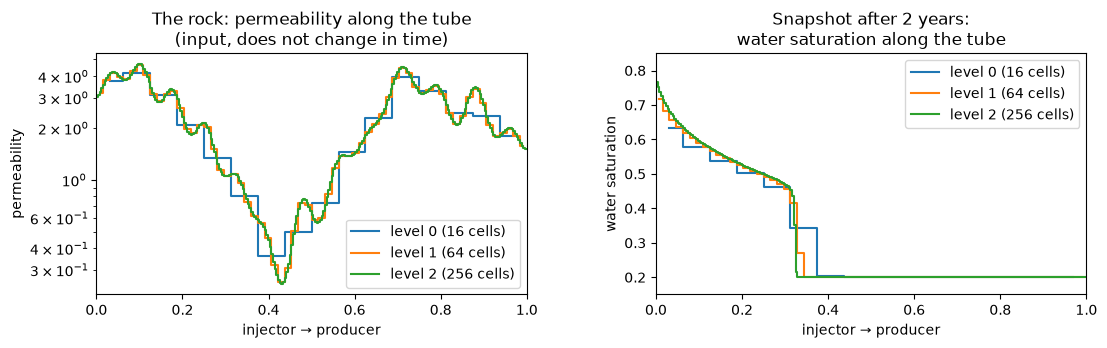

In [2]:
theta = rng.standard_normal(N_THETA)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for level in range(3):
    xc = (np.arange(CELLS[level]) + 0.5) / CELLS[level]
    _, S = simulate(theta, level, t_end=0.2 * T_END, return_state=True)
    ax[0].step(xc, permeability(theta, level), where="mid", label=f"level {level} ({CELLS[level]} cells)")
    ax[1].step(xc, S, where="mid", label=f"level {level} ({CELLS[level]} cells)")
    print(f"level {level}: P = {simulate(theta, level):.2f} % after 10 years")
ax[0].set(yscale="log", xlim=(0, 1), xlabel="injector → producer", ylabel="permeability",
          title="The rock: permeability along the tube\n(input, does not change in time)")
ax[1].set(xlim=(0, 1), ylim=(0.15, 0.85), xlabel="injector → producer", ylabel="water saturation",
          title="Snapshot after 2 years:\nwater saturation along the tube")
ax[0].legend(); ax[1].legend()
fig.subplots_adjust(left=0.08, right=0.98, bottom=0.15, top=0.82, wspace=0.3)   # same layout as the animation below
plt.show()

The same rock, from 0 to 10 years:

<img src="figures/water_front_levels.gif" alt="Animation: water saturation along the tube on the three grids, from 0 to 10 years" style="max-width: 100%;">

*Made with [figures/water_front_levels.py](figures/water_front_levels.py).*

- Coarse grid: the water front spreads out, water arrives earlier, less oil → **bias**.
- Same rock gives similar answers on all grids → **coupling** → small corrections $P_\ell - P_{\ell-1}$.

## 3. MLMC step by step

Four steps: test runs → number of samples → estimate → bias check.

In [3]:
# Tables below: show HTML in headers (e.g. V<sub>ℓ</sub> as a subscript), set once for every DataFrame
get_ipython().display_formatter.formatters["text/html"].for_type(pd.DataFrame, lambda df: df.to_html(escape=False));

### Step 1: test runs, estimate $C_\ell$ and $V_\ell$

In [4]:
def sample_level(level, n, rng):
    # n independent samples on one level: returns P_l and the corrections P_l - P_{l-1} (level 0: P_0)
    P, D = np.empty(n), np.empty(n)
    for i in range(n):
        theta = rng.standard_normal(N_THETA)             # a new rock for every sample
        P[i] = simulate(theta, level)
        D[i] = P[i] - simulate(theta, level - 1) if level > 0 else P[i]
    return P, D


N_PILOT = 20
p, d, t = [], [], []                                     # per level: values P_l, corrections, time of each sample
for l in range(3):
    runs = []
    for _ in range(N_PILOT):
        t0 = time.perf_counter()
        runs.append((*sample_level(l, 1, rng), time.perf_counter() - t0))   # level l > 0: both runs of the pair
    P, D, T = map(np.concatenate, zip(*[(a, b, [s]) for a, b, s in runs]))
    p.append(P); d.append(D); t.append(1000 * T)
C = np.array([x.mean() for x in t]) / 1000              # C_l in seconds, used in step 2

groups = {"time per sample (ms)": ("mean C<sub>ℓ</sub>", "variance"),
          "value P<sub>ℓ</sub>": ("mean", "variance 𝕍[P<sub>ℓ</sub>]"),
          "correction P<sub>ℓ</sub> − P<sub>ℓ−1</sub>": ("mean", "variance V<sub>ℓ</sub>")}
cols = pd.MultiIndex.from_tuples([("samples", "")] + [(g, s) for g, (m, v) in groups.items() for s in (m, v, "standard deviation")])
levels = pd.Index([f"{l} ({n} cells)" for l, n in enumerate(CELLS)], name="level ℓ")
rows = [[x.size, *[stat for z in (ti, x, y) for stat in (z.mean(), z.var(ddof=1), z.std(ddof=1))]] for x, y, ti in zip(p, d, t)]
V_col = cols[-2]                                         # V_l is small: show more decimals
pd.DataFrame(rows, columns=cols, index=levels).round({col: 4 if col == V_col else 2 for col in cols})

samples time per sample (ms)                              \
                        mean C<sub>ℓ</sub> variance standard deviation   
level ℓ                                                                  
0 (16 cells)       20                 0.52     0.16               0.40   
1 (64 cells)       20                 2.30     2.33               1.53   
2 (256 cells)      20                12.78   124.51              11.16   

              value P<sub>ℓ</sub>                            \
                             mean variance 𝕍[P<sub>ℓ</sub>]   
level ℓ                                                       
0 (16 cells)                37.46                    269.49   
1 (64 cells)                43.59                    188.93   
2 (256 cells)               45.31                    230.80   

                                 correction P<sub>ℓ</sub> − P<sub>ℓ−1</sub>  \
              standard deviation                                       mean   
level ℓ                                                                       
0 (16 cells)               16.42                                      37.46   
1 (64 cells)               13.75                                       1.15   
2 (256 cells)              15.19                                       0.40   

                                                         
              variance V<sub>ℓ</sub> standard deviation  
level ℓ                                                  
0 (16 cells)                269.4899              16.42  
1 (64 cells)                  0.2981               0.55  
2 (256 cells)                 0.0161               0.13

20 samples per level, each with a **new** $\theta$. On level $\ell \ge 1$ a sample is a **pair**: the same $\theta$ on this level and the next coarser one, so it costs both runs.

- **Needed next:** $C_\ell$ (mean time) and $V_\ell$ (variance of the correction).
- $\mathbb{V}[P_\ell]$ does **not** shrink with the level: it is the rock-to-rock spread (SD ≈ 14 points; the table differences are noise). Only the correction shrinks: $V_\ell$ gets smaller with every finer level (269 → 0.30 → 0.016), because the same rock on both grids cancels most of the spread.
- The mean of $P_\ell$ increases with the level: coarse grids smear out the water front, so water reaches the producer earlier and less oil is recovered (the size of the increase also depends on randomness).

### Step 2: best number of samples, $N_\ell$

Target: mean squared error $\text{MSE} \le \varepsilon^2$ (here $\varepsilon = 0.5$ points). It has two parts (Giles 2015, p. 264, eq. 2.1): $\text{MSE} = \text{variance} + \text{bias}^2$. Give each part half of $\varepsilon^2$ (a simple choice): variance $\le \varepsilon^2/2$ (enough samples, this step) and $\text{bias}^2 \le \varepsilon^2/2$ (fine enough grid, step 4). For the variance part, the cheapest choice is:

$$
N_\ell = \mu \sqrt{V_\ell / C_\ell}, \qquad \mu = \frac{1}{f\varepsilon^2} \sum_{k} \sqrt{V_k C_k}
$$

$f$ = share of $\varepsilon^2$ given to the variance; here $f = 1/2$, so $\mu = \frac{2}{\varepsilon^2} \sum_k \sqrt{V_k C_k}$. The split only changes $\mu$: all $N_\ell$ scale by $1/f$, their ratios stay the same.

Run the extra samples, update $V_\ell$, compute $N_\ell$ again. Repeat until no more samples are needed (Algorithm 1, p. 279).

In [5]:
EPS = 0.5                                              # target RMSE, percentage points


def optimal_N(d):
    V = np.array([x.var(ddof=1) for x in d])
    mu = np.sum(np.sqrt(V * C)) / (EPS**2 / 2)
    return np.ceil(mu * np.sqrt(V / C)).astype(int)


rounds = []
for it in range(5):
    N_opt = optimal_N(d)
    extra = np.maximum(N_opt - [x.size for x in d], 0)
    rounds.append([*N_opt, *extra])
    if extra.sum() == 0:
        break
    for l in range(3):
        if extra[l] > 0:
            P_new, D_new = sample_level(l, extra[l], rng)
            p[l], d[l] = np.concatenate((p[l], P_new)), np.concatenate((d[l], D_new))

cols = pd.MultiIndex.from_product([["optimal N<sub>ℓ</sub>", "extra samples"], ["ℓ = 0", "ℓ = 1", "ℓ = 2"]])
pd.DataFrame(rounds, columns=cols).rename_axis("round")

optimal N<sub>ℓ</sub>             extra samples            
                      ℓ = 0 ℓ = 1 ℓ = 2         ℓ = 0 ℓ = 1 ℓ = 2
round                                                            
0                      2389    38     4          2369    18     0
1                      1785    31     4             0     0     0

- $V_0$ from only 20 test samples is not accurate → $N_0$ changes after the first round. This is why we repeat.
- Level 2: the 20 test samples are already more than the best $N_2$. With a real simulator, start with fewer fine samples.

### Step 3: the estimate and its error

Estimate: $Y = \sum_\ell \text{mean}(P_\ell - P_{\ell-1})$. Its variance: $\sum_\ell V_\ell / N_\ell$.

In [6]:
N = np.array([x.size for x in d])
V = np.array([x.var(ddof=1) for x in d])
Y = sum(x.mean() for x in d)
se = np.sqrt(np.sum(V / N))
cost_mlmc = np.sum(N * C)

display(pd.DataFrame({
    "N<sub>ℓ</sub>": N,
    "mean of P<sub>ℓ</sub> − P<sub>ℓ−1</sub> (sum = Y)": np.round([x.mean() for x in d], 2),
    "V<sub>ℓ</sub>": np.round(V, 4),
    "C<sub>ℓ</sub> (ms)": np.round(1000 * C, 2),
    "spending N<sub>ℓ</sub>·C<sub>ℓ</sub> (s)": np.round(N * C, 2),
}).rename_axis("level ℓ"))
print(f"MLMC estimate of E[P_fine]: {Y:.2f} % ± {2 * se:.2f} (2 standard errors)")
print(f"compute cost: {cost_mlmc:.1f} s")

,Nℓ,mean of Pℓ − Pℓ−1 (sum = Y),Vℓ,Cℓ (ms),spending Nℓ·Cℓ (s)
level ℓ,,,,,
0,2389,41.52,199.3611,0.52,1.25
1,38,1.15,0.2527,2.30,0.09
2,20,0.40,0.0161,12.78,0.26


MLMC estimate of E[P_fine]: 43.07 % ± 0.60 (2 standard errors)
compute cost: 1.6 s


Where the printed numbers come from (rounded; they change a little with each run, because $C_\ell$ is timed):

- Estimate $Y$ = sum of the column "mean of $P_\ell - P_{\ell-1}$": $41.52 + 1.15 + 0.40 = 43.07$ %.
- ± error = 2 standard errors $= 2\sqrt{\sum_\ell V_\ell / N_\ell}$, from the columns $V_\ell$ and $N_\ell$: $199.36/2389 + 0.2527/38 + 0.0161/20 \approx 0.091$, so $2\sqrt{0.091} \approx 0.60$.
- Compute cost = sum of the last column, $N_\ell C_\ell$: $1.25 + 0.09 + 0.26 = 1.6$ s.

### Step 4: is the bias small enough?

Estimate the remaining bias from the last correction (p. 279). If the corrections become smaller like $M^{-\alpha\ell}$ ($M = 4$ here):

$$
|\mathbb{E}[P - P_2]| \approx \frac{|\mathbb{E}[P_2 - P_1]|}{M^\alpha - 1}
$$

This must be less than $\varepsilon/\sqrt{2}$. If not, **add a finer level** and start again from step 1.

alpha ≈ 0.76, remaining bias ≈ 0.21, limit ε/√2 = 0.35
three levels are enough


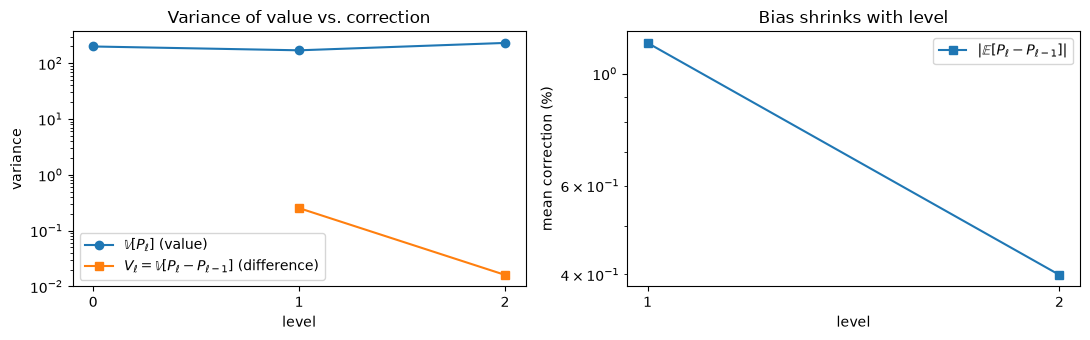

In [7]:
m = np.array([abs(x.mean()) for x in d])
alpha = np.log(m[1] / m[2]) / np.log(M)
bias = m[2] / (M**alpha - 1)
print(f"alpha ≈ {alpha:.2f}, remaining bias ≈ {bias:.2f}, limit ε/√2 = {EPS / np.sqrt(2):.2f}")
print("three levels are enough" if bias < EPS / np.sqrt(2) else "bias too large: add a finer level")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
lv = np.arange(3)
ax[0].semilogy(lv, [x.var(ddof=1) for x in p], "o-", label=r"$\mathbb{V}[P_\ell]$ (value)")
ax[0].semilogy(lv[1:], V[1:], "s-", label=r"$V_\ell = \mathbb{V}[P_\ell - P_{\ell-1}]$ (difference)")
ax[0].set(xlabel="level", ylabel="variance", xticks=lv, title="Variance of value vs. correction")
ax[1].semilogy(lv[1:], m[1:], "s-", label=r"$|\mathbb{E}[P_\ell - P_{\ell-1}]|$")
ax[1].set(xlabel="level", ylabel="mean correction (%)", xticks=lv[1:], title="Bias shrinks with level")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

- Here the remaining bias is 0.21 < 0.35, so three levels are enough.
- Optional: add the estimated bias to the result, $43.07 + 0.21 \approx 43.28$ %. This is Richardson extrapolation (Giles 2015, §2.3, p. 269). It reduces the bias but usually increases the noise (standard error); here only slightly, 2 SE goes from 0.603 to about 0.604 (delta method), since most of the noise comes from level 0.

## 4. Check: plain Monte Carlo with only the fine grid

Same target variance $\varepsilon^2/2$, but only fine runs. $\mathbb{V}[P_\text{fine}] \approx \mathbb{V}[P_0]$, which we know well from the many level-0 samples. Takes 10–20 s.

In [8]:
N_plain = int(np.ceil(p[0].var(ddof=1) / (EPS**2 / 2)))
t0 = time.perf_counter()
P_plain = np.array([simulate(rng.standard_normal(N_THETA), 2) for _ in range(N_plain)])
cost_plain = time.perf_counter() - t0

print(f"plain MC: {N_plain} fine runs, estimate {P_plain.mean():.2f} % ± {2 * P_plain.std(ddof=1) / np.sqrt(N_plain):.2f}, cost {cost_plain:.1f} s")
print(f"MLMC:     {N.tolist()} samples, estimate {Y:.2f} % ± {2 * se:.2f}, cost {cost_mlmc:.1f} s")
print(f"MLMC is about {cost_plain / cost_mlmc:.0f}x cheaper for the same accuracy")

plain MC: 1595 fine runs, estimate 43.12 % ± 0.73, cost 14.1 s
MLMC:     [2389, 38, 20] samples, estimate 43.07 % ± 0.60, cost 1.6 s
MLMC is about 9x cheaper for the same accuracy


Both methods give the same answer (within the error bars), but MLMC needs much less computing time.

## 5. What changes with a real simulator

- One run takes minutes to hours → run the samples as many jobs in parallel on a cluster.
- Use only a few test runs on the fine levels (they are expensive). Here 20 were more than needed on level 2.
- A fine run costs much more than a coarse run (e.g. 10 h vs 5 min) → MLMC saves even more time.
- Few fine samples → $V_\ell$ is not accurate. Giles uses the coarser levels to set a lower limit for it (p. 280).

**Reference:** M. B. Giles (2015), Multilevel Monte Carlo methods, *Acta Numerica*, pp. 259–328.